# Практическая работа: классификация военных и гражданских самолётов

**Дисциплина:** Интеллектуальные системы и технологии  
**Выполнили:** Абрамов Сергей, Ахундов Орхан, Руднев Илья, Марков Никита.  
**Цель:** Сравнить качество бинарной классификации изображений самолётов двумя мультимодальными моделями.

Используются **SmolVLM2-500M** и **SmolVLM2-256M**, опубликованные на Hugging Face. Модели запускаются **локально в Google Colab с GPU**, через библиотеку Transformers.

**Данные:** 30 фотографий самолётов (15 гражданских и 15 военных), включая нетривиальные варианты. Изображения находятся в `dataset/`, эталонные классы и категории — в `metadata.csv`. Исходный набор передаётся отдельным ZIP-архивом `aircraft_dataset_for_classmate.zip`.

**Метрики:** Accuracy, Precision, Recall, F1 (положительный класс — `military`), точность на сложных примерах, средняя задержка ответа, матрицы ошибок.


## 1. Загрузка датасета

Загрузите ZIP-архив с папкой `dataset/` и файлом `metadata.csv`. При повторном запуске в свежей среде Colab ZIP необходимо загрузить заново.


In [1]:
from google.colab import files
import zipfile
import io

# Выбираем наш ZIP-архив
uploaded = files.upload()

zip_name = next(
    name for name in uploaded
    if name.endswith(".zip")
)

# Распаковываем фотографии и metadata.csv
with zipfile.ZipFile(io.BytesIO(uploaded[zip_name])) as archive:
    archive.extractall("/content")

print("Датасет успешно загружен!")

Saving aircraft_dataset_for_classmate.zip to aircraft_dataset_for_classmate.zip
Датасет успешно загружен!


In [2]:
import pandas as pd
from pathlib import Path

df = pd.read_csv("/content/metadata.csv")

print("Всего самолётов:", len(df))
print("Столбцы:", df.columns.tolist())

missing = [
    filename
    for filename in df["filename"]
    if not (Path("/content/dataset") / filename).exists()
]

print("Отсутствующие фотографии:", missing)

display(df.head())

Всего самолётов: 30
Столбцы: ['filename', 'true_label', 'category', 'aircraft_name', 'id']
Отсутствующие фотографии: []


,filename,true_label,category,aircraft_name,id
0,C01.jpg,civilian,basic_civilian,Airbus A320 family,C01
1,C02.jpg,civilian,basic_civilian,Boeing 737,C02
2,C03.jpg,civilian,basic_civilian,Airbus A380,C03
3,C04.jpg,civilian,basic_civilian,Boeing 747,C04
4,C05.jpg,civilian,basic_civilian,Boeing 787 Dreamliner,C05


## 2. Установка библиотек и проверка GPU

Для запуска нужен доступный GPU в Colab (например, T4): **Среда выполнения → Сменить среду выполнения → T4 GPU**. Установка `num2words` до импорта `transformers` предотвращает ошибку инициализации процессора SmolVLM2.


In [3]:
%pip -q install transformers accelerate num2words scikit-learn matplotlib seaborn pillow tqdm pandas


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import torch

print("GPU доступен:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))

GPU доступен: True
Видеокарта: Tesla T4


## 3. Методика эксперимента

Каждому изображению передаётся одинаковая англоязычная инструкция: определить один из двух классов (`civilian` / `military`). Каждая модель обрабатывает все 30 изображений в одном и том же порядке. Для ответа используется детерминированная генерация (`do_sample=False`); результат сохраняется после обработки каждого снимка.

При технической ошибке модель возвращает `error`; такая запись не является предсказанием. До вычисления сравнительных метрик следует проверить, что **обе модели дали по 30 допустимых ответов**. Задержка измеряется в текущей среде Colab, поэтому она зависит от GPU и условий запуска.


In [5]:
import os
import re
import gc
import time
import torch
import pandas as pd

from pathlib import Path
from tqdm.notebook import tqdm
from transformers import pipeline

assert torch.cuda.is_available(), "Необходимо включить GPU"

MODELS = {
    "SmolVLM2-500M":
        "HuggingFaceTB/SmolVLM2-500M-Video-Instruct",
    "SmolVLM2-256M":
        "HuggingFaceTB/SmolVLM2-256M-Video-Instruct"
}

PROMPT = (
    "Look at the aircraft in this image. "
    "Is it military or civilian? "
    "Answer with exactly one lowercase word: "
    "military or civilian."
)

df = pd.read_csv("metadata.csv")
results_df = df.copy()

# Основной эксперимент: все 30 фотографий.
MAX_IMAGES = 30

for model_name, model_id in MODELS.items():

    print(f"\nЗагружаем модель: {model_name}")

    pipe = pipeline(
        "image-text-to-text",
        model=model_id,
        device=0,
        dtype=torch.float16
    )

    for idx, row in tqdm(
        df.head(MAX_IMAGES).iterrows(),
        total=min(MAX_IMAGES, len(df)),
        desc=model_name
    ):
        start = time.perf_counter()

        try:
            image_path = str(
                (Path("dataset") / row["filename"]).resolve()
            )

            messages = [{
                "role": "user",
                "content": [
                    {"type": "image", "path": image_path},
                    {"type": "text", "text": PROMPT}
                ]
            }]

            output = pipe(
                text=messages,
                max_new_tokens=12,
                do_sample=False,
                return_full_text=False
            )

            raw = output[0]["generated_text"]

            if isinstance(raw, list):
                raw = " ".join(
                    str(x.get("text", ""))
                    for x in raw
                    if isinstance(x, dict)
                )

            raw = str(raw).strip()

            found = re.findall(
                r"\b(?:military|civilian)\b",
                raw.lower()
            )

            label = (
                found[0]
                if found and len(set(found)) == 1
                else "unknown"
            )

        except Exception as e:
            label = "error"
            raw = str(e)

        results_df.loc[idx, f"{model_name}_pred"] = label
        results_df.loc[idx, f"{model_name}_reason"] = raw
        results_df.loc[idx, f"{model_name}_time"] = round(
            time.perf_counter() - start, 2
        )

        results_df.to_csv(
            "evaluation_results.csv", index=False
        )

        print(
            row["filename"],
            "Истина:", row["true_label"],
            "Ответ:", label
        )

    del pipe
    gc.collect()
    torch.cuda.empty_cache()

display(results_df.head())


Загружаем модель: SmolVLM2-500M


config.json:   0%|          | 0.00/3.77k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.03GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/489 [00:00<?, ?it/s]

...

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


M13.jpg Истина: military Ответ: military


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


M14.jpg Истина: military Ответ: civilian
M15.jpg Истина: military Ответ: civilian


,filename,true_label,category,aircraft_name,id,SmolVLM2-500M_pred,SmolVLM2-500M_reason,SmolVLM2-500M_time,SmolVLM2-256M_pred,SmolVLM2-256M_reason,SmolVLM2-256M_time
0,C01.jpg,civilian,basic_civilian,Airbus A320 family,C01,civilian,civilian,3.62,civilian,civilian.,0.77
1,C02.jpg,civilian,basic_civilian,Boeing 737,C02,civilian,civilian,0.72,civilian,civilian.,0.68
2,C03.jpg,civilian,basic_civilian,Airbus A380,C03,civilian,civilian,0.70,civilian,civilian.,0.68
3,C04.jpg,civilian,basic_civilian,Boeing 747,C04,civilian,civilian,0.65,civilian,civilian.,0.67
4,C05.jpg,civilian,basic_civilian,Boeing 787 Dreamliner,C05,civilian,civilian,0.69,civilian,civilian.,0.69


## 4. Проверка полноты результатов

Проверяем, что каждая модель классифицировала **30 из 30** фотографий, без `error`, `unknown` и пропусков. При неполном наборе метрики ниже нельзя считать сопоставимыми.


In [6]:
for model_name in MODELS:
    column = f"{model_name}_pred"

    print(f"\nМодель: {model_name}")
    print(results_df[column].value_counts(dropna=False))

    valid = results_df[column].isin(
        ["civilian", "military"]
    ).sum()

    print(f"Успешных классификаций: {valid}/30")


Модель: SmolVLM2-500M
SmolVLM2-500M_pred
military    16
civilian    14
Name: count, dtype: int64
Успешных классификаций: 30/30

Модель: SmolVLM2-256M
SmolVLM2-256M_pred
civilian    21
military     9
Name: count, dtype: int64
Успешных классификаций: 30/30


## 5. Количественное сравнение

**Accuracy** — доля верно классифицированных изображений. **Precision** для класса `military` — доля действительно военных среди предсказанных военных; **Recall** — доля обнаруженных военных среди всех военных; **F1** — гармоническое среднее Precision и Recall. «Сложные случаи» — записи, категория которых отличается от `basic_civilian` и `basic_military`.


In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns

def calculate_metrics(df: pd.DataFrame, model_prefix: str) -> dict:
    valid_df = df[df[f"{model_prefix}_pred"].isin(["military", "civilian"])]
    if len(valid_df) == 0:
        return {"Model": model_prefix}

    y_true = valid_df["true_label"]
    y_pred = valid_df[f"{model_prefix}_pred"]

    hard_df = valid_df[~valid_df["category"].isin(["basic_civilian", "basic_military"])]
    hard_acc = accuracy_score(hard_df["true_label"], hard_df[f"{model_prefix}_pred"]) if len(hard_df) > 0 else 0

    return {
        "Model": model_prefix,
        "Accuracy (All)": round(accuracy_score(y_true, y_pred), 3),
        "Accuracy (Hard Cases)": round(hard_acc, 3),
        "Precision (Military)": round(precision_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "Recall (Military)": round(recall_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "F1-Score": round(f1_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "Avg Latency (s)": round(valid_df[f"{model_prefix}_time"].mean(), 2)
    }

metrics_list = [calculate_metrics(results_df, m) for m in MODELS.keys()]
metrics_table = pd.DataFrame(metrics_list).set_index("Model")
display(metrics_table)

,Accuracy (All),Accuracy (Hard Cases),Precision (Military),Recall (Military),F1-Score,Avg Latency (s)
Model,,,,,,
SmolVLM2-500M,0.967,0.95,0.938,1.0,0.968,0.80
SmolVLM2-256M,0.800,0.85,1.000,0.6,0.750,0.76


## 6. Матрицы ошибок

По строкам указан истинный класс, по столбцам — предсказанный. Числа на диагонали отражают правильные ответы, вне диагонали — ошибки.


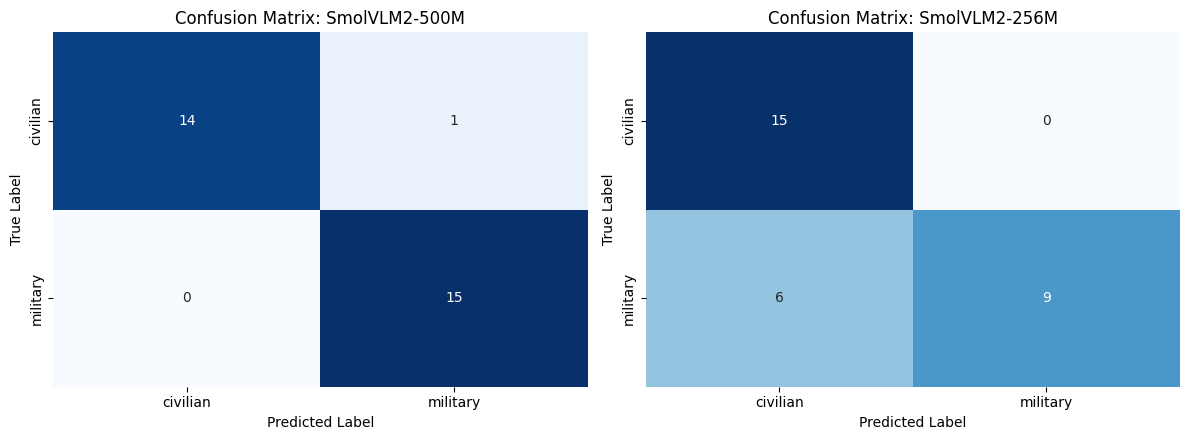

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ["civilian", "military"]

for ax, model_name in zip(axes, MODELS.keys()):
    valid_df = results_df[results_df[f"{model_name}_pred"].isin(labels)]
    if len(valid_df) == 0: continue
    cm = confusion_matrix(valid_df["true_label"], valid_df[f"{model_name}_pred"], labels=labels)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()

## 7. Анализ ошибочных классификаций

Анализируются конкретные самолёты, для которых ответ модели отличается от эталонной метки. Поскольку внешний вид и реальное назначение конкретного борта могут расходиться, эталонные метки следует интерпретировать как разметку, принятую в этом датасете.


In [9]:
for model_name in MODELS:
    print(f"\nОшибки модели {model_name}")

    mistakes = results_df[
        results_df["true_label"] !=
        results_df[f"{model_name}_pred"]
    ]

    display(mistakes[[
        "aircraft_name",
        "category",
        "true_label",
        f"{model_name}_pred"
    ]])


Ошибки модели SmolVLM2-500M


,aircraft_name,category,true_label,SmolVLM2-500M_pred
14,Lockheed L-100 Hercules,hard_civilian,civilian,military



Ошибки модели SmolVLM2-256M


,aircraft_name,category,true_label,SmolVLM2-256M_pred
15,F-35 Lightning II,basic_military,military,civilian
16,F-22 Raptor,basic_military,military,civilian
17,F-16 Fighting Falcon,basic_military,military,civilian
24,F/A-18 Super Hornet,medium_military,military,civilian
28,P-8 Poseidon,hard_military,military,civilian
29,KC-46 Pegasus,hard_military,military,civilian


## 8. Выводы

На наборе из **30 фотографий** (15 гражданских, 15 военных) модель **SmolVLM2-500M** верно классифицировала **29 из 30** изображений (Accuracy **96,67%**), а **SmolVLM2-256M** — **24 из 30** (Accuracy **80,00%**). F1 для класса `military` составил соответственно **96,8%** и **75,0%**; Recall — **100%** и **60%**. На 20 нетривиальных примерах модели достигли точности **95%** и **85%** соответственно. Среднее измеренное время на изображение составляло примерно **0,70 с** и **0,99 с** в этой среде Colab.

У SmolVLM2-500M одна ошибка: гражданский **Lockheed L-100 Hercules** классифицирован как военный. Это сложный случай, поскольку конструкция семейства Hercules тесно связана с военной транспортной авиацией. У SmolVLM2-256M шесть военных самолётов были ошибочно отнесены к гражданским: **F-35 Lightning II, F-22 Raptor, F-16 Fighting Falcon, F/A-18 Super Hornet, P-8 Poseidon, KC-46 Pegasus**. При этом SmolVLM2-256M не отнесла ни одного гражданского самолёта к военным.

**Заключение:** в пределах данной небольшой выборки SmolVLM2-500M обеспечила более высокую общую точность и лучше обнаруживала военные самолёты. Однако результаты на 30 снимках не являются основанием для обобщения на всю авиацию, а правильность эталонной классификации пограничных случаев зависит от принятого критерия. Модели взяты с Hugging Face и запускались **на GPU Colab, не через Hugging Face Inference Providers**.


## 9. Сохранение результатов

Сохраните `evaluation_results.csv` и таблицу метрик вместе с ноутбуком. Для повторения эксперимента приложите отдельный ZIP с 30 изображениями и `metadata.csv`.


In [10]:
results_df.to_csv("evaluation_results.csv", index=False)
metrics_table.to_csv("model_metrics.csv")
print("Созданы: evaluation_results.csv и model_metrics.csv")
print("Для передачи работы скачайте .ipynb, оба CSV и ZIP-архив датасета.")


Созданы: evaluation_results.csv и model_metrics.csv
Для передачи работы скачайте .ipynb, оба CSV и ZIP-архив датасета.
